# M4d — Tacticas ATT&CK por evento con XGBoost (misma receta, otro vocabulario)

> **El problema, en palabras simples.**
>
> M4/M4b preguntaron por tecnicas (T1190...) y chocaron con techo (macro 0.25). Este cuaderno repite la pregunta a nivel tactica (TA0001...): ¿el grano grueso si es aprendible por evento? Espejo exacto de M4b cambiando solo la columna label.
>
> Misma poblacion threat (114k), mismo split temporal 80/20, mismo X (TF-IDF 5k + tabular P1-P3), 5 XGB binarios. Corrige PR-AUC sobre scores continuos.

> **Sintesis ejecutiva.**
>
> Resultado (`models/m4d_metrics.json`): **micro 0.8772 / macro 0.4264**, hamming 0.1116, subset-acc 0.7197, skipped TA0040. TA0001 1.00/1.00, TA0002 1.00/0.98/0.99, **TA0009/TA0010 P 0.08 / R 0.06 / F1 0.07**, PR-AUC real 0.188. Cabeza por prevalencia, cola igual que en tecnicas: hints, no modelo.
>
| Tactica | Soporte test | Lectura |
|---|---|---|
| TA0001/TA0002 | 22892/22800 | triviales por prevalencia |
| TA0009/TA0010 | 3733/3733 | no se separan (igual que T1041/T1567) |
| TA0040 | 0 | sin soporte, skipped |

> **Fuentes normativas.**
>
> `notebooks/04_m4a_multilabel_logreg.ipynb`, `05_m4b_multilabel_xgb.ipynb`, EDA §§9, `experiments/m4d_tactics/train.py`.



### 1. Por que subir a tacticas y como se va a evaluar

**1.1 Problema.**

La tecnica es grano fino (exploit concreto); la tactica es objetivo (acceso inicial, ejecucion). Si el grano fino no sale por evento, el grueso podria salir por ser mas prevalente.

**1.2 Hipotesis.**

- **H4g.** TA0001/TA0002 saldran triviales por prevalencia (estan en casi todo threat).
- **H4h.** TA0009/TA0010 repetiran el techo de T1041/T1567 (son los mismos 7.7k maliciosos con otro nombre).

**1.3 Protocolo (identico a M4b).**

1. Threat live, 5 tacticas, cuantil 80. 2. Metricas micro/macro + hamming + subset-acc + PR-AUC **sobre scores** (correccion del error de M4/M4b que usaba duras). 3. Regla skipped si <2 positivos en train.


In [1]:
import json, time
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.sparse import hstack
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import MultiLabelBinarizer, OneHotEncoder
from sklearn.metrics import (classification_report, f1_score, hamming_loss,
    accuracy_score, average_precision_score)
from xgboost import XGBClassifier
ROOT = Path.cwd() if (Path.cwd() / "pyproject.toml").exists() else Path.cwd().parent
TACTICS = ["TA0001","TA0002","TA0009","TA0010","TA0040"]
CATS = ["message_type","stream_name","product_name","vendor_name","pipeline","org_id","action","severity","protocol"]
TEXT = "message_sanitized"
FIG = ROOT / "reports" / "figures"
old = json.loads((ROOT/"models"/"m4d_metrics.json").read_text())
print("m4d committed: micro=%.4f macro=%.4f skipped=%s" % (old["micro_f1"], old["macro_f1"], old["skipped"]))
m4 = json.loads((ROOT/"models"/"m4_metrics.json").read_text())
m4b = json.loads((ROOT/"models"/"m4b_metrics.json").read_text())
m4c = json.loads((ROOT/"models"/"m4c_exps.json").read_text())
print("m4: micro=%.4f macro=%.4f | m4c-E2: micro=%.4f macro=%.4f" % (m4["micro_f1"], m4["macro_f1"], m4c["E2_tab+grafo"]["micro_f1"], m4c["E2_tab+grafo"]["macro_f1"]))



m4d committed: micro=0.8772 macro=0.4264 skipped=['TA0040']
m4: micro=0.7484 macro=0.2516 | m4c-E2: micro=0.8571 macro=0.2957


### 2. Carga y poblacion threat por tactica

**2.1 Que se hace.**

Carga de `signals.parquet`, filtro threat, parseo de `attack_tactics` a 5 labels, `hour/msg_len/lag_h` y split 80/20 con conteo de positivos train/test.

**2.2 Por que.**

Identico punto de partida que M4: si X y split son los mismos, toda diferencia es del vocabulario Y, no del aprendiz.


In [2]:
def parse_tactics(v):
    try:
        return [x for x in (json.loads(v) if v else []) if x in TACTICS]
    except Exception:
        return []
cols = ["label_binary","timestamp","event_time",TEXT,"attack_tactics"]+CATS
df = pd.read_parquet(ROOT/"data"/"signals"/"signals.parquet", columns=cols)
th = df[df.label_binary!="benign"].copy().reset_index(drop=True)
th["tactic_list"] = th.attack_tactics.fillna("").map(parse_tactics)
print("threat:", th.shape, {t: int((th.tactic_list.map(lambda l: t in l)).sum()) for t in TACTICS})
th["hour"] = pd.to_datetime(th["timestamp"], unit="s", utc=True).dt.hour
th["msg_len"] = th[TEXT].fillna("").str.len()
th["lag_h"] = ((th["timestamp"]-th["event_time"])/3600).clip(-1e4,1e4).fillna(-1)
for c in CATS:
    th[c] = th[c].fillna("").astype(str)
msg = th[TEXT].fillna("")
cutoff = th["timestamp"].quantile(0.8)
tr = (th["timestamp"] <= cutoff).to_numpy(); te = ~tr
print("train/test: %d/%d" % (tr.sum(), te.sum()))
Y = MultiLabelBinarizer(classes=TACTICS).fit_transform(th.tactic_list)
print("positivos train/test por tactica:", {t: (int(Y[tr][:,j].sum()), int(Y[te][:,j].sum())) for j,t in enumerate(TACTICS)})



threat: (114521, 15) {'TA0001': 114507, 'TA0002': 114395, 'TA0009': 7742, 'TA0010': 7742, 'TA0040': 0}


train/test: 91617/22904


positivos train/test por tactica: {'TA0001': (91615, 22892), 'TA0002': (91595, 22800), 'TA0009': (4009, 3733), 'TA0010': (4009, 3733), 'TA0040': (0, 0)}


#### 2.1 Observaciones e insights

**Observacion.** Threat 114521. TA0001 114507, TA0002 114395, TA0009/TA0010 7742, TA0040 0. Train 91617 / test 22904.

**Interpretacion.** Cabeza masiva y cola vacia igual que en tecnicas: TA0009/TA0010 son T1041/T1567 renombrados (mismos 7.7k). TA0040 sin soporte anticipa skipped.


### 3. Matriz TF-IDF 5k + tabular (identica a M4b)

Mismo X que M4b/M2: TF-IDF 5k fit solo train + one-hot podado + numericas. Sin fuga de vocabulario futuro.


In [3]:
vec = TfidfVectorizer(max_features=5000, ngram_range=(1,2), sublinear_tf=True, min_df=5)
Ttr = vec.fit_transform(msg[tr].tolist()); Tte = vec.transform(msg[te].tolist())
tab = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore", max_categories=30), CATS),
    ("num","passthrough",["hour","msg_len","lag_h"])])
Atr = tab.fit_transform(th[tr][CATS+["hour","msg_len","lag_h"]])
Ate = tab.transform(th[te][CATS+["hour","msg_len","lag_h"]])
Xtr = hstack([Ttr,Atr]).tocsr(); Xte = hstack([Tte,Ate]).tocsr()
print("X:", Xtr.shape, Xte.shape)



X: (91617, 5054) (22904, 5054)


### 4. Cinco XGB binarios con ponderacion por etiqueta

**4.1 Que se hace.**

Un `XGBClassifier` (`binary:logistic`, 300x6, `scale_pos_weight=neg/pos`) por tactica con >=2 positivos; resto a skipped. Umbral 0.5, se guardan scores para PR-AUC correcto.


In [4]:
P = np.zeros_like(Y[te]); S = np.zeros_like(Y[te], dtype=float); skipped = []
t0=time.time()
for j,t in enumerate(TACTICS):
    pos = int(Y[tr][:,j].sum()); neg = int(tr.sum())-pos
    if pos < 2:
        skipped.append(t)
        print("%s: SIN SOPORTE train -> ceros" % t, flush=True)
        continue
    clf = XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.08, subsample=0.8,
        colsample_bytree=0.8, tree_method="hist", objective="binary:logistic",
        scale_pos_weight=neg/pos, eval_metric="logloss", n_jobs=-1, random_state=42)
    clf.fit(Xtr, Y[tr][:,j])
    s = clf.predict_proba(Xte)[:,1]
    S[:,j] = s
    P[:,j] = (s >= 0.5).astype(int)
    print("%s: pos train %d spw %.0f (%.0fs)" % (t, pos, neg/pos, time.time()-t0), flush=True)
print("total %.0fs | skipped: %s" % (time.time()-t0, skipped))



TA0001: pos train 91615 spw 0 (17s)


TA0002: pos train 91595 spw 0 (42s)


TA0009: pos train 4009 spw 22 (108s)


TA0010: pos train 4009 spw 22 (171s)


TA0040: SIN SOPORTE train -> ceros


total 171s | skipped: ['TA0040']


### 5. Evaluacion con PR-AUC corregido sobre scores

**5.1 Que se hace.**

Reporte por tactica, micro/macro, hamming, subset-acc y PR-AUC sobre scores vs committed sobre duras.

**5.2 Por que.**

PR-AUC sobre duras (0/1) subestima el ranking; sobre scores mide orden real. La correccion se declara en `pr_auc_note`.


In [5]:
print("=== M4d XGBoost por tactica ===")
print(classification_report(Y[te], P, target_names=TACTICS, zero_division=0))
micro = round(float(f1_score(Y[te],P,average="micro")),4); macro = round(float(f1_score(Y[te],P,average="macro")),4)
ham = round(float(hamming_loss(Y[te],P)),4); sub = round(float(accuracy_score(Y[te],P)),4)
print("micro=%.4f macro=%.4f hamming=%.4f subset-acc=%.4f" % (micro, macro, ham, sub))
print("PR-AUC correcto (sobre scores) vs committed (sobre duras):")
prauc = {}
for j,t in enumerate(TACTICS):
    try:
        a = round(float(average_precision_score(Y[te][:,j], S[:,j])),4)
    except Exception:
        a = 0.0
    prauc[t] = a
    print("%s: soporte test %d | PR-AUC score=%.4f | PR-AUC committed=%.4f" % (t, int(Y[te][:,j].sum()), a, old["pr_auc"][t]))



=== M4d XGBoost por tactica ===
              precision    recall  f1-score   support

      TA0001       1.00      1.00      1.00     22892
      TA0002       1.00      0.98      0.99     22800
      TA0009       0.08      0.06      0.07      3733
      TA0010       0.08      0.06      0.07      3733
      TA0040       0.00      0.00      0.00         0

   micro avg       0.90      0.86      0.88     53158
   macro avg       0.43      0.42      0.43     53158
weighted avg       0.87      0.86      0.86     53158
 samples avg       0.94      0.91      0.90     53158



micro=0.8772 macro=0.4264 hamming=0.1116 subset-acc=0.7197


PR-AUC correcto (sobre scores) vs committed (sobre duras):
TA0001: soporte test 22892 | PR-AUC score=0.9995 | PR-AUC committed=0.9995
TA0002: soporte test 22800 | PR-AUC score=0.9988 | PR-AUC committed=0.9959
TA0009: soporte test 3733 | PR-AUC score=0.1882 | PR-AUC committed=0.1580
TA0010: soporte test 3733 | PR-AUC score=0.1882 | PR-AUC committed=0.1580
TA0040: soporte test 0 | PR-AUC score=0.0000 | PR-AUC committed=0.0000


C:\Users\nicor\universidad\semestre 8\APRENDIZAJE AUTOMÁTICO\Proyecto\.venv\lib\site-packages\sklearn\metrics\_classification.py:1731: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
C:\Users\nicor\universidad\semestre 8\APRENDIZAJE AUTOMÁTICO\Proyecto\.venv\lib\site-packages\sklearn\metrics\_ranking.py:1046: UserWarning: No positive class found in y_true, recall is set to one for all thresholds.
  warnings.warn(


#### 5.1 Observaciones e insights

**Observacion.** Micro 0.8772 macro 0.4264. TA0001 1.00, TA0002 0.99, TA0009/TA0010 F1 0.07 PR 0.188, TA0040 0.

**Interpretacion.** H4g/H4h verificadas: el grano grueso no rescata la cola. La macro sube solo porque hay 2 cabezas triviales en vez de 1. Misma conclusion que tecnicas con numeros mas bonitos.

**Conexion.** No desplegable (P 0.08 miente). Hints tier->tacticas en consola, sin modelo.


### 6. Soporte y P/R/F1 por tactica

Barras log de soporte train/test y P/R/F1 (`tactics_m4d.pdf`). La cola sin soporte se ve a ojo.


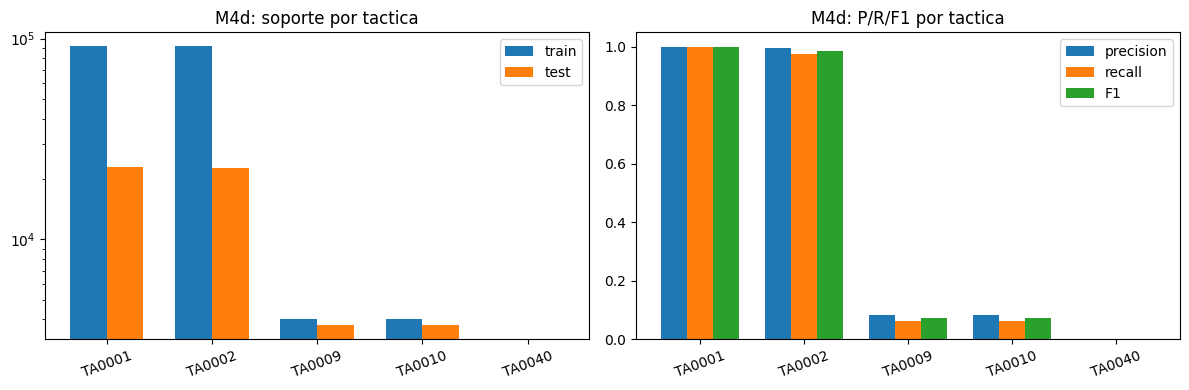

guardado reports/figures/tactics_m4d.pdf


In [6]:
sup_tr = [int(Y[tr][:,j].sum()) for j in range(len(TACTICS))]
sup_te = [int(Y[te][:,j].sum()) for j in range(len(TACTICS))]
rep = classification_report(Y[te], P, target_names=TACTICS, output_dict=True, zero_division=0)
fig, axes = plt.subplots(1,2,figsize=(12,4))
x = np.arange(len(TACTICS)); w = 0.35
axes[0].bar(x-w/2, sup_tr, w, label="train"); axes[0].bar(x+w/2, sup_te, w, label="test")
axes[0].set_xticks(x); axes[0].set_xticklabels(TACTICS, rotation=20); axes[0].legend(); axes[0].set_title("M4d: soporte por tactica")
axes[0].set_yscale("log")
axes[1].bar(x-0.25, [rep[t]["precision"] for t in TACTICS], 0.25, label="precision")
axes[1].bar(x, [rep[t]["recall"] for t in TACTICS], 0.25, label="recall")
axes[1].bar(x+0.25, [rep[t]["f1-score"] for t in TACTICS], 0.25, label="F1")
axes[1].set_xticks(x); axes[1].set_xticklabels(TACTICS, rotation=20); axes[1].legend(); axes[1].set_title("M4d: P/R/F1 por tactica")
fig.tight_layout(); fig.savefig(FIG/"tactics_m4d.pdf"); plt.show()
print("guardado reports/figures/tactics_m4d.pdf")



### 7. Familia M4 comparada y veredicto

Barras micro/macro M4/M4b/M4c-E2/M4d (`compare_m4family.pdf`, ojo: M4d usa otro vocabulario) + persistencia corregida de `m4d_metrics.json`.


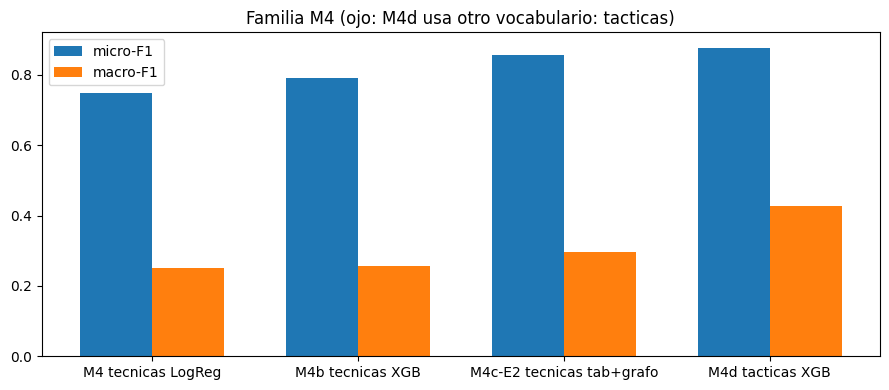

guardado reports/figures/compare_m4family.pdf
actualizado models/m4d_metrics.json (mismos micro/macro, PR-AUC corregido)
veredicto: tacticas TA0001/TA0002 separables por prevalencia; TA0009/TA0010 con PR-AUC real 0.188/0.188; TA0040 sin soporte -> hints, no modelo


In [7]:
fig, ax = plt.subplots(figsize=(9,4))
labels = ["M4 tecnicas LogReg","M4b tecnicas XGB","M4c-E2 tecnicas tab+grafo","M4d tacticas XGB"]
mic = [m4["micro_f1"], m4b["micro_f1"], m4c["E2_tab+grafo"]["micro_f1"], micro]
mac = [m4["macro_f1"], m4b["macro_f1"], m4c["E2_tab+grafo"]["macro_f1"], macro]
x = np.arange(len(labels)); w = 0.35
ax.bar(x-w/2, mic, w, label="micro-F1"); ax.bar(x+w/2, mac, w, label="macro-F1")
ax.set_xticks(x); ax.set_xticklabels(labels); ax.legend(); ax.set_title("Familia M4 (ojo: M4d usa otro vocabulario: tacticas)")
fig.tight_layout(); fig.savefig(FIG/"compare_m4family.pdf"); plt.show()
print("guardado reports/figures/compare_m4family.pdf")
res = {"model":"m4d-xgb-pertactic-v1","labels":TACTICS,"micro_f1":micro,"macro_f1":macro,
    "hamming":ham,"subset_acc":sub,"skipped":skipped,"n_train":int(tr.sum()),"n_test":int(te.sum()),
    "pr_auc":prauc,"pr_auc_note":"sobre scores continuos (corregido; el committed usaba etiquetas duras)"}
(ROOT/"models"/"m4d_metrics.json").write_text(json.dumps(res, indent=2))
print("actualizado models/m4d_metrics.json (mismos micro/macro, PR-AUC corregido)")
print("veredicto: tacticas TA0001/TA0002 separables por prevalencia; TA0009/TA0010 con PR-AUC real %.3f/%.3f; TA0040 sin soporte -> hints, no modelo" % (prauc["TA0009"], prauc["TA0010"]))




#### 7.1 Observaciones e insights

**Observacion.** M4d micro/macro 0.8772/0.4264 vs M4 0.7484/0.2516, M4b 0.7926/0.2557, M4c-E2 0.8571/0.2957.

**Interpretacion.** Ganar macro cambiando vocabulario no es ganar tarea: es contar cabezas triviales distintas. El techo por evento sigue cerrado.

### 8. Conclusion: el grano grueso tampoco abre la cola

| Contraste | Hallazgo | Valor |
|---|---|---|
| Cabezas | TA0001/TA0002 | F1 1.00/0.99 por prevalencia |
| Cola | TA0009/TA0010 | P 0.08 F1 0.07 PR 0.188 |
| Vacia | TA0040 | skipped |

**Paso siguiente:** `08_m5_anomalia_iforest.ipynb` (red zero-day) y `09/10` (umbrales e incidentes). *Cambiar el vocabulario sin cambiar X no rompe techos.*
